<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# DBSCAN and More!

_Author:_ Tim Book

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn import metrics
from scipy.cluster.hierarchy import dendrogram

In [2]:
names = [
    'area', 'perimeter', 'compactness',
    'kern_len', 'kern_width', 'asymmetry',
    'groove_width', 'variety'
]
seeds = pd.read_csv('data/seeds_dataset.txt', sep='\s+', names=names)
seeds.head()

,area,perimeter,compactness,kern_len,kern_width,asymmetry,groove_width,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


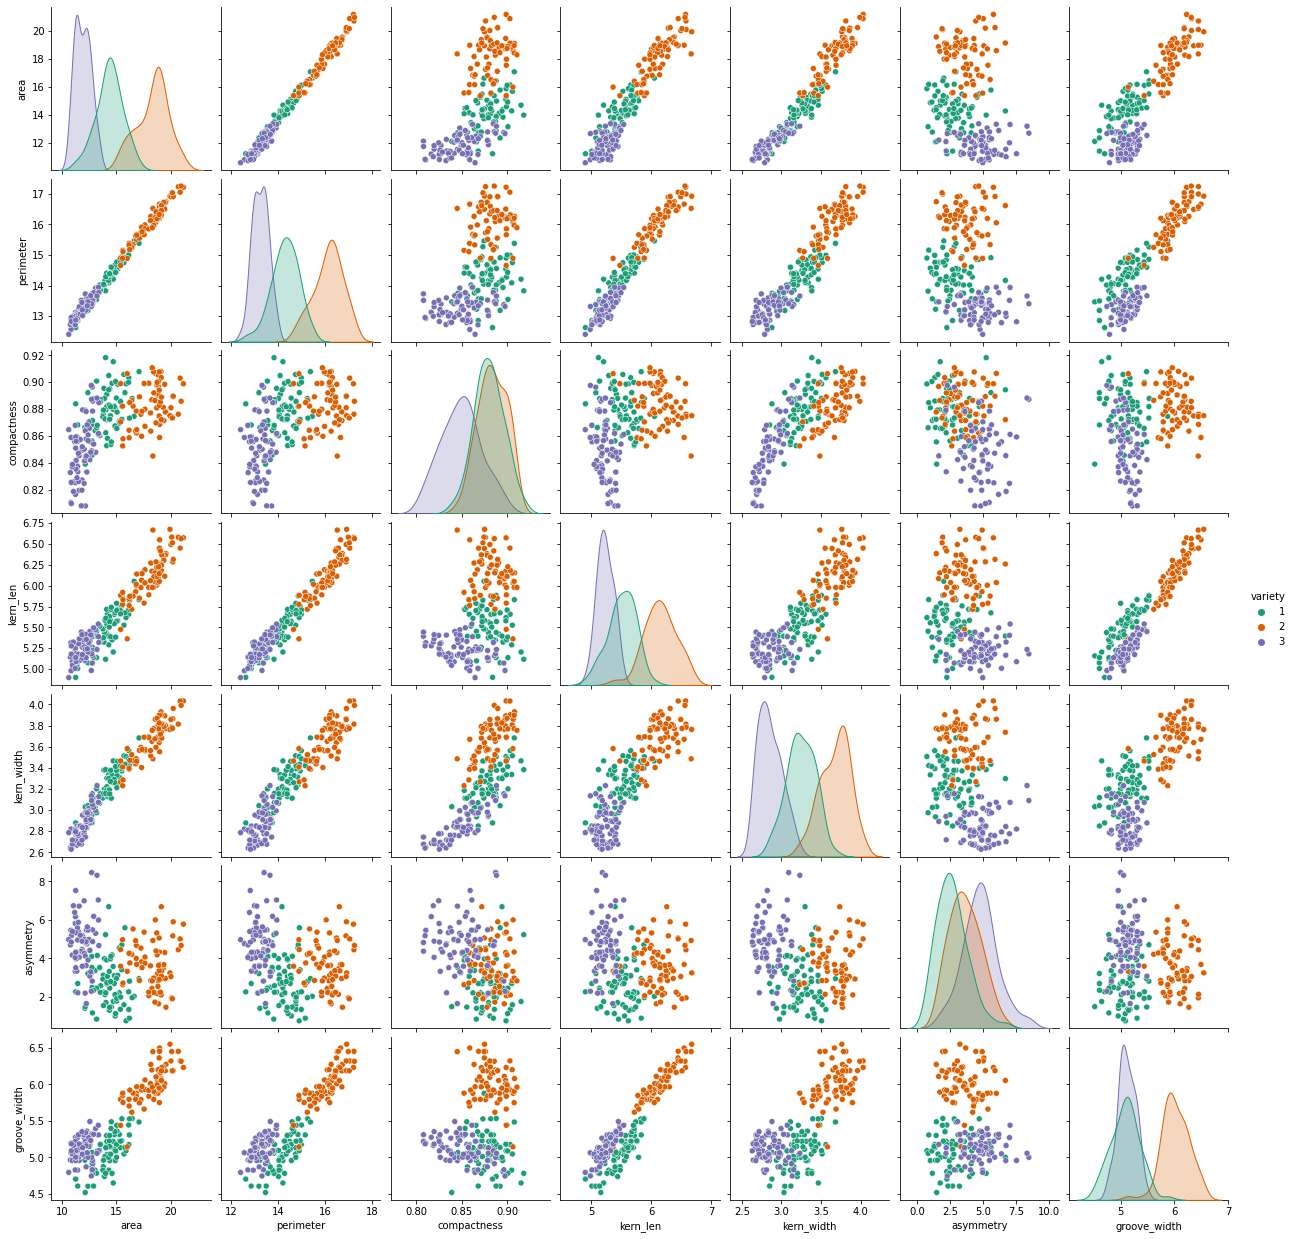

In [3]:
# Some fast EDA
sns.pairplot(seeds, hue='variety', palette='Dark2');

In [4]:
# Let's use ONLY kernel width and groove width to do our clustering.
# (YOU) make me an X and standard scale it!
X = seeds[['kern_width', 'groove_width']]
Z = StandardScaler().fit_transform(X)

In [5]:
# Let's fit a DBSCAN with epsilon = 0.3 and n = 7
db = DBSCAN(eps=0.3, min_samples=7)
db.fit(Z)

DBSCAN(eps=0.3, min_samples=7)

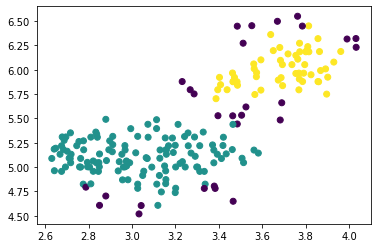

In [6]:
# Let's plot our clusters on the original data scale and color them in.
plt.scatter(X.kern_width, X.groove_width, c=db.labels_)

## Model Evaluation: Silhouette Score
---

Recall the formula for silhouette score:

### $s_i = \frac{b_i - a_i}{max\{a_i, b_i\}}$

Where:
- $a_i$ = Cohesion: Average distance of points within clusters
- $b_i$ = Separation: Average distance from point $x_i$ to all points in the next nearest cluster.

In the cell below, use the `silhouette_score` function from `sklearn` to evaluate our `DBSCAN` model.

In [7]:
# What's the silhouette score of our DBSCAN(0.3, 7) cluster?
metrics.silhouette_score(Z, db.labels_)

0.4331166977120715

-0.4872295806218845

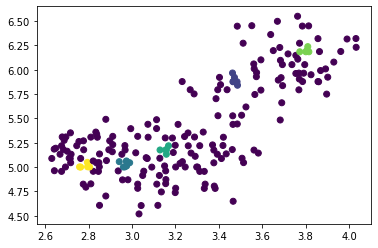

In [8]:
# Put everything in one cell here and rapidly iterate epsilon and cluster
db = DBSCAN(eps=0.1, min_samples=5)
db.fit(Z)
plt.scatter(X.kern_width, X.groove_width, c=db.labels_)
metrics.silhouette_score(Z, db.labels_)

In [9]:
# Painful, but you *could* brute force the params
e_vec = np.linspace(0.01, 0.7, 100)
n_vec = np.arange(1, 15)
res = []

for e in e_vec:
    for n in n_vec:
        cl = DBSCAN(eps=e, min_samples=n)
        cl.fit(Z)
        lbls = pd.Series(cl.labels_)
        if lbls.nunique() <= 1:
            continue
            
        sil = metrics.silhouette_score(Z, cl.labels_)
        res.append((e, n, sil))

In [10]:
df_res = pd.DataFrame(res, columns=['e', 'n', 'sil'])

In [11]:
df_res.sort_values('sil', ascending=False)

,e,n,sil
684,0.539697,14,0.615489
683,0.539697,13,0.615489
663,0.504848,11,0.568014
644,0.483939,10,0.539827
631,0.470000,10,0.539827
...,...,...,...
10,0.037879,2,-0.550148
7,0.030909,2,-0.552945
26,0.072727,3,-0.554083
5,0.023939,2,-0.602787


0.6154893353164566

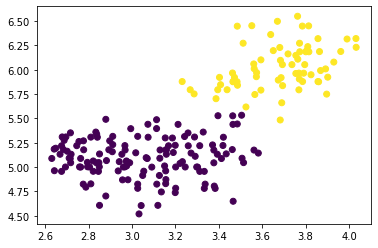

In [12]:
db = DBSCAN(eps=0.54, min_samples=14)
db.fit(Z)
plt.scatter(X.kern_width, X.groove_width, c=db.labels_)
metrics.silhouette_score(Z, db.labels_)

# Agglomerative (Hierarchical) Clustering
**Hierarchical clustering** is a technique in which we join or split successive clusters. We can plot such a models' **dendrogram** if we want, too!

In [13]:
# Let's fit an agglomerative clusterer with 3 clusters.
agglom = AgglomerativeClustering(3)
agglom.fit(Z)

AgglomerativeClustering(n_clusters=3)

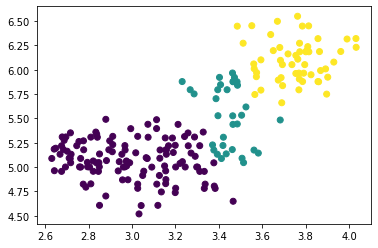

In [14]:
# Let's see it visually
plt.scatter(X.kern_width, X.groove_width, c=agglom.labels_);

In [15]:
# Silhouette?
metrics.silhouette_score(Z, agglom.labels_)

0.43908974634556064

In [16]:
# STOLEN FROM SKLEARN DOCS HERE!!
# https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html
def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

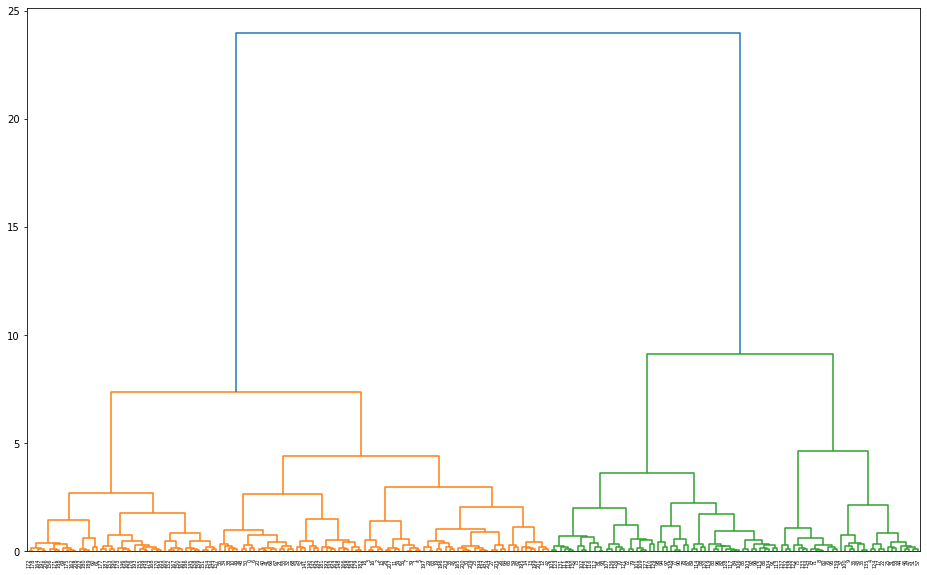

In [17]:
# These arguments are required to fit the whole tree. We can't plot the whole tree
# without computing it!
agglom = AgglomerativeClustering(n_clusters=None, distance_threshold=0)
agglom.fit(Z)

plt.figure(figsize=(16, 10))
plot_dendrogram(agglom)

# DBSCAN conclusions
* DBSCAN is an interesting one in that it clusters based on the density of clusters...
* However, it comes at the cost of needing TWO (2!) tuning parameters.
* DBSCAN can also help us detect **outliers**.

# Agglomerative clustering conclusions
* Distance-based clustering algo that starts with every observation separate and successively joins clusters.
* Allows us to see the "path" of joins based similarity.
* Can plot nice **dendrograms**, although not always as useful as you'd think.

# Clustering Conclusions
Clustering is one of the two most common use cases for **unsupervised learning** (the other being dimensionality reduction). 

* It's used to segment your data into groups where members of one cluster are most similar to eachother than they are to observations in other groups.
* This process is totally independent of a $y$-variable! It only uses your $x$s.
* Almost all of these techniques rely on computing **distance metrics** between points, so **scaling** is important!
* There are many, many clustering algorithms out there and in sklearn! [Here are the ones we can enjoy via sklearn](https://scikit-learn.org/stable/modules/clustering.html#clustering).
* $k$-Means is probably the most well-known and therefore most commonly used.
* Although Tim's favorite, [k-medoids clustering](https://en.wikipedia.org/wiki/K-medoids), is a popular choice too, and it's not even contained in sklearn! It is very similar to k-means, though.
